In [52]:
import pandas as pd
raw = pd.read_csv(r"C:\Users\alfia\Global Video Game Sales & Ratings/Raw Data.csv")
raw.head()

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [53]:
# Menampilkan ringkasan informasi dari dataset
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  str    
 1   Platform         16719 non-null  str    
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  str    
 4   Publisher        16665 non-null  str    
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  str    
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  str    
 15  Rating           9950 non-null   str    
dtypes: float64(9), str(7)
memory usage: 2.0 MB


In [54]:
# Menampilkan statistik deskriptif dari dataset
raw.describe(include="all")

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
count,16717,16719,16450.000000,16717,16665,16719.000000,16719.000000,16719.000000,16719.000000,16719.000000,8137.000000,8137.000000,10015,7590.000000,10096,9950
unique,11562,31,NaN,12,581,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96,NaN,1696,8
top,Need for Speed: Most Wanted,PS2,NaN,Action,Electronic Arts,NaN,NaN,NaN,NaN,NaN,NaN,NaN,tbd,NaN,Ubisoft,E
freq,12,2161,NaN,3370,1356,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2425,NaN,204,3991
mean,NaN,NaN,2006.487356,NaN,NaN,0.263330,0.145025,0.077602,0.047332,0.533543,68.967679,26.360821,NaN,162.229908,NaN,NaN
std,NaN,NaN,5.878995,NaN,NaN,0.813514,0.503283,0.308818,0.186710,1.547935,13.938165,18.980495,NaN,561.282326,NaN,NaN
min,NaN,NaN,1980.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.010000,13.000000,3.000000,NaN,4.000000,NaN,NaN
25%,NaN,NaN,2003.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.060000,60.000000,12.000000,NaN,10.000000,NaN,NaN
50%,NaN,NaN,2007.000000,NaN,NaN,0.080000,0.020000,0.000000,0.010000,0.170000,71.000000,21.000000,NaN,24.000000,NaN,NaN
75%,NaN,NaN,2010.000000,NaN,NaN,0.240000,0.110000,0.040000,0.030000,0.470000,79.000000,36.000000,NaN,81.000000,NaN,NaN


In [55]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = raw.isnull().sum()
missing_values[missing_values > 0]

Name                  2
Year_of_Release     269
Genre                 2
Publisher            54
Critic_Score       8582
Critic_Count       8582
User_Score         6704
User_Count         9129
Developer          6623
Rating             6769
dtype: int64

In [56]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [57]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = raw[less].select_dtypes(include=['number']).columns
raw[numeric_features] = raw[numeric_features].fillna(raw[numeric_features].median())

In [58]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = raw[less].select_dtypes(include=['str']).columns
for column in kategorical_features:
    raw[column] = raw[column].fillna(raw[column].mode()[0])

In [59]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = raw.drop(columns=over)

In [60]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

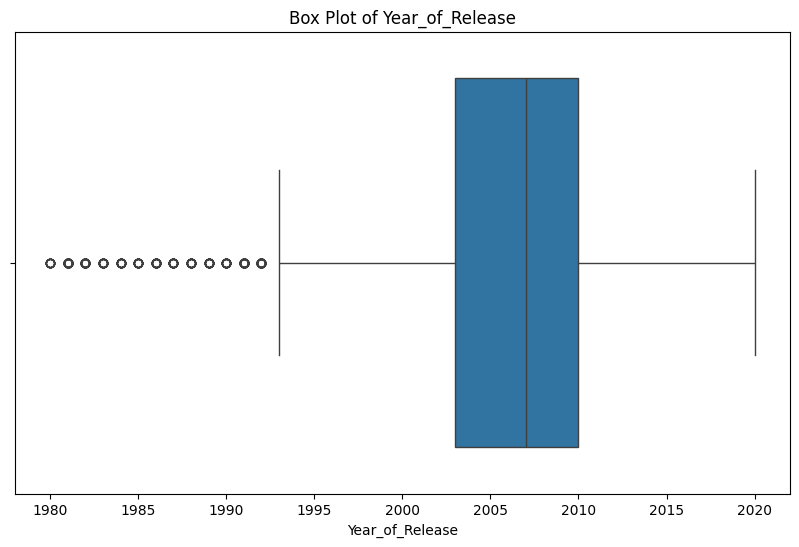

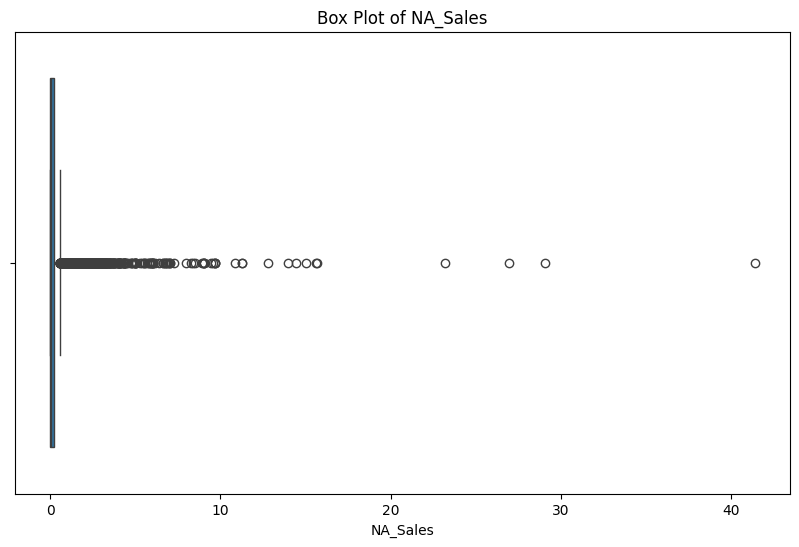

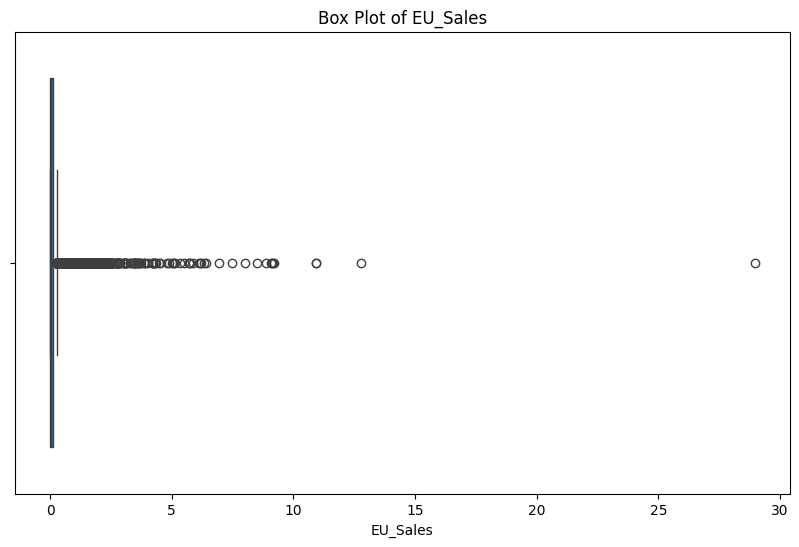

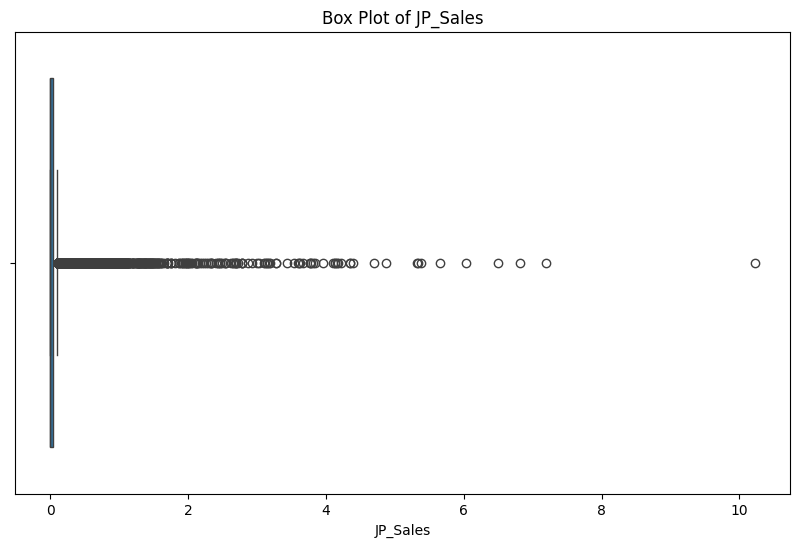

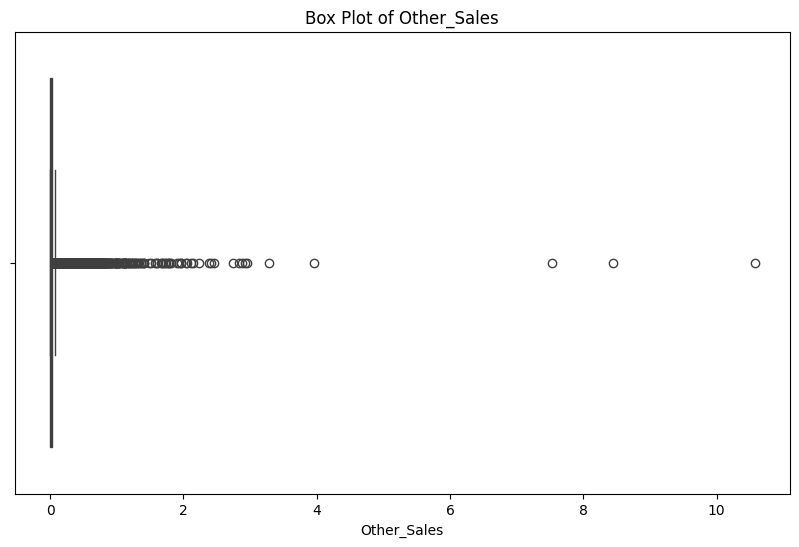

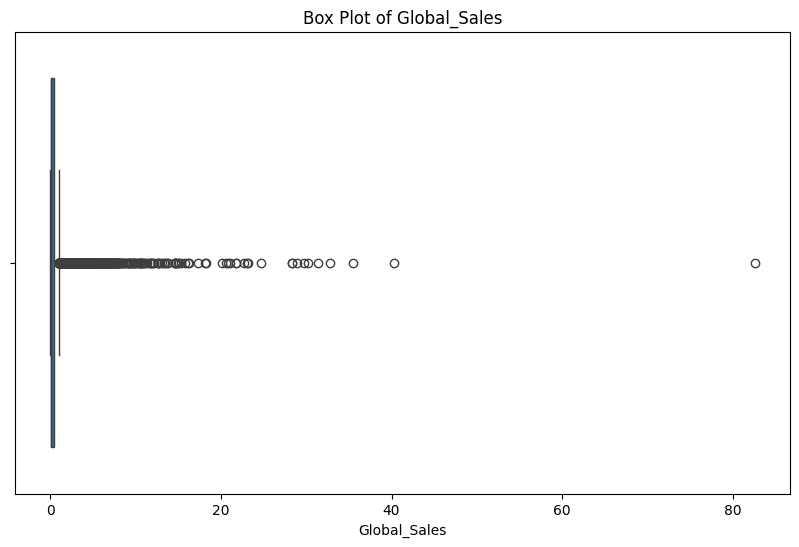

In [61]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
  
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [62]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [63]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['str']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [64]:
# Mengganti outlier dengan nilai median
for column in numeric_features:
    Q1_col = df[column].quantile(0.25)
    Q3_col = df[column].quantile(0.75)
    IQR_col = Q3_col - Q1_col

    lower_bound = Q1_col - 1.5 * IQR_col
    upper_bound = Q3_col + 1.5 * IQR_col

    median = df[column].median()

    df[column] = df[column].apply(
        lambda x: median if x < lower_bound or x > upper_bound else x
    )

In [65]:
# Mengganti outlier dengan nilai batas terdekat
for column in numeric_features:
    Q1_col = df[column].quantile(0.25)
    Q3_col = df[column].quantile(0.75)
    IQR_col = Q3_col - Q1_col

    lower_bound = Q1_col - 1.5 * IQR_col
    upper_bound = Q3_col + 1.5 * IQR_col

    df[column] = df[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

In [66]:
from sklearn.preprocessing import StandardScaler
  
# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

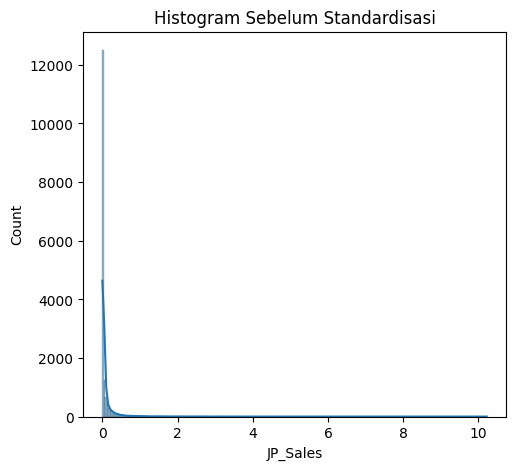

In [67]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(raw[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

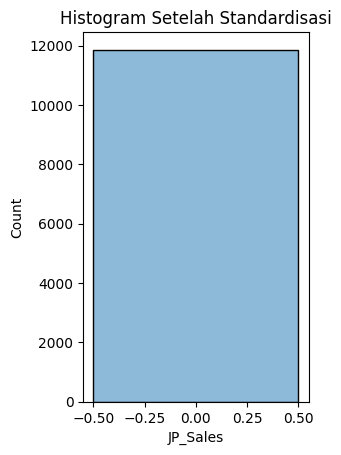

In [68]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [69]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
  
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Year_of_Release, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales, Name, Platform, Genre, Publisher]
Index: []


In [70]:
# Menghapus baris duplikat
df = df.drop_duplicates()
  
print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
       Year_of_Release  NA_Sales  EU_Sales  JP_Sales  Other_Sales  \
2323         -1.321510 -0.202767 -0.065907       0.0     1.262859   
2384          0.994970 -0.202767 -0.065907       0.0     0.170241   
2413          0.363203 -0.202767 -0.065907       0.0     0.170241   
2426          0.573792 -0.202767 -0.065907       0.0     0.170241   
2471         -0.689743 -0.202767 -0.065907       0.0     0.170241   
...                ...       ...       ...       ...          ...   
16714         1.837326 -0.932189 -0.874714       0.0    -0.922377   
16715        -0.268565 -0.932189 -0.470310       0.0    -0.922377   
16716         1.837326 -0.932189 -0.874714       0.0    -0.922377   
16717        -0.900332 -0.810618 -0.874714       0.0    -0.922377   
16718         1.837326 -0.932189 -0.874714       0.0    -0.922377   

       Global_Sales                             Name Platform         Genre  \
2323      -0.253977  Castlevania: Circle of the Moon  

In [71]:
category_features = df.select_dtypes(include=['object', 'str']).columns
df[category_features]

,Name,Platform,Genre,Publisher
2323,Castlevania: Circle of the Moon,GBA,Platform,Konami Digital Entertainment
2384,Kingdoms of Amalur: Reckoning,X360,Role-Playing,Electronic Arts
2413,Ghostbusters: The Video Game,Wii,Action,Atari
2426,Pictionary,Wii,Puzzle,THQ
2471,Metroid: Zero Mission,GBA,Adventure,Nintendo
...,...,...,...,...
16714,Samurai Warriors: Sanada Maru,PS3,Action,Tecmo Koei
16715,LMA Manager 2007,X360,Sports,Codemasters
16716,Haitaka no Psychedelica,PSV,Adventure,Idea Factory
16717,Spirits & Spells,GBA,Platform,Wanadoo


In [72]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Name_ Beyblade Burst,Name_ Frozen: Olaf's Quest,Name_ Haikyu!! Cross Team Match!,Name_.hack//G.U. Vol.2//Reminisce,...,Publisher_Zoo Digital Publishing,Publisher_Zoo Games,Publisher_Zushi Games,Publisher_bitComposer Games,Publisher_dramatic create,Publisher_fonfun,Publisher_iWin,Publisher_imageepoch Inc.,Publisher_inXile Entertainment,Publisher_responDESIGN
2323,-1.321510,-0.202767,-0.065907,0.0,1.262859,-0.253977,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2384,0.994970,-0.202767,-0.065907,0.0,0.170241,-0.253977,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2413,0.363203,-0.202767,-0.065907,0.0,0.170241,-0.253977,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2426,0.573792,-0.202767,-0.065907,0.0,0.170241,-0.253977,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2471,-0.689743,-0.202767,-0.065907,0.0,0.170241,-0.253977,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16714,1.837326,-0.932189,-0.874714,0.0,-0.922377,-1.059630,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
16715,-0.268565,-0.932189,-0.470310,0.0,-0.922377,-1.059630,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
16716,1.837326,-0.932189,-0.874714,0.0,-0.922377,-1.059630,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
16717,-0.900332,-0.810618,-0.874714,0.0,-0.922377,-1.059630,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [73]:
from sklearn.preprocessing import LabelEncoder
  
# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)
  
for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])
  
# Menampilkan hasil
df_lencoder

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Name,Platform,Genre,Publisher
2323,-1.321510,-0.202767,-0.065907,0.0,1.262859,-0.253977,1104,6,4,254
2384,0.994970,-0.202767,-0.065907,0.0,0.170241,-0.253977,3810,27,7,126
2413,0.363203,-0.202767,-0.065907,0.0,0.170241,-0.253977,2777,25,0,48
2426,0.573792,-0.202767,-0.065907,0.0,0.170241,-0.253977,5543,25,5,447
2471,-0.689743,-0.202767,-0.065907,0.0,0.170241,-0.253977,4486,6,1,328
...,...,...,...,...,...,...,...,...,...,...
16714,1.837326,-0.932189,-0.874714,0.0,-0.922377,-1.059630,6330,16,0,457
16715,-0.268565,-0.932189,-0.470310,0.0,-0.922377,-1.059630,3926,27,10,80
16716,1.837326,-0.932189,-0.874714,0.0,-0.922377,-1.059630,2994,19,1,214
16717,-0.900332,-0.810618,-0.874714,0.0,-0.922377,-1.059630,6841,6,4,498


In [74]:
df_lencoder.head()

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Name,Platform,Genre,Publisher
2323,-1.321510,-0.202767,-0.065907,0.0,1.262859,-0.253977,1104,6,4,254
2384,0.994970,-0.202767,-0.065907,0.0,0.170241,-0.253977,3810,27,7,126
2413,0.363203,-0.202767,-0.065907,0.0,0.170241,-0.253977,2777,25,0,48
2426,0.573792,-0.202767,-0.065907,0.0,0.170241,-0.253977,5543,25,5,447
2471,-0.689743,-0.202767,-0.065907,0.0,0.170241,-0.253977,4486,6,1,328


In [75]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
  
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage


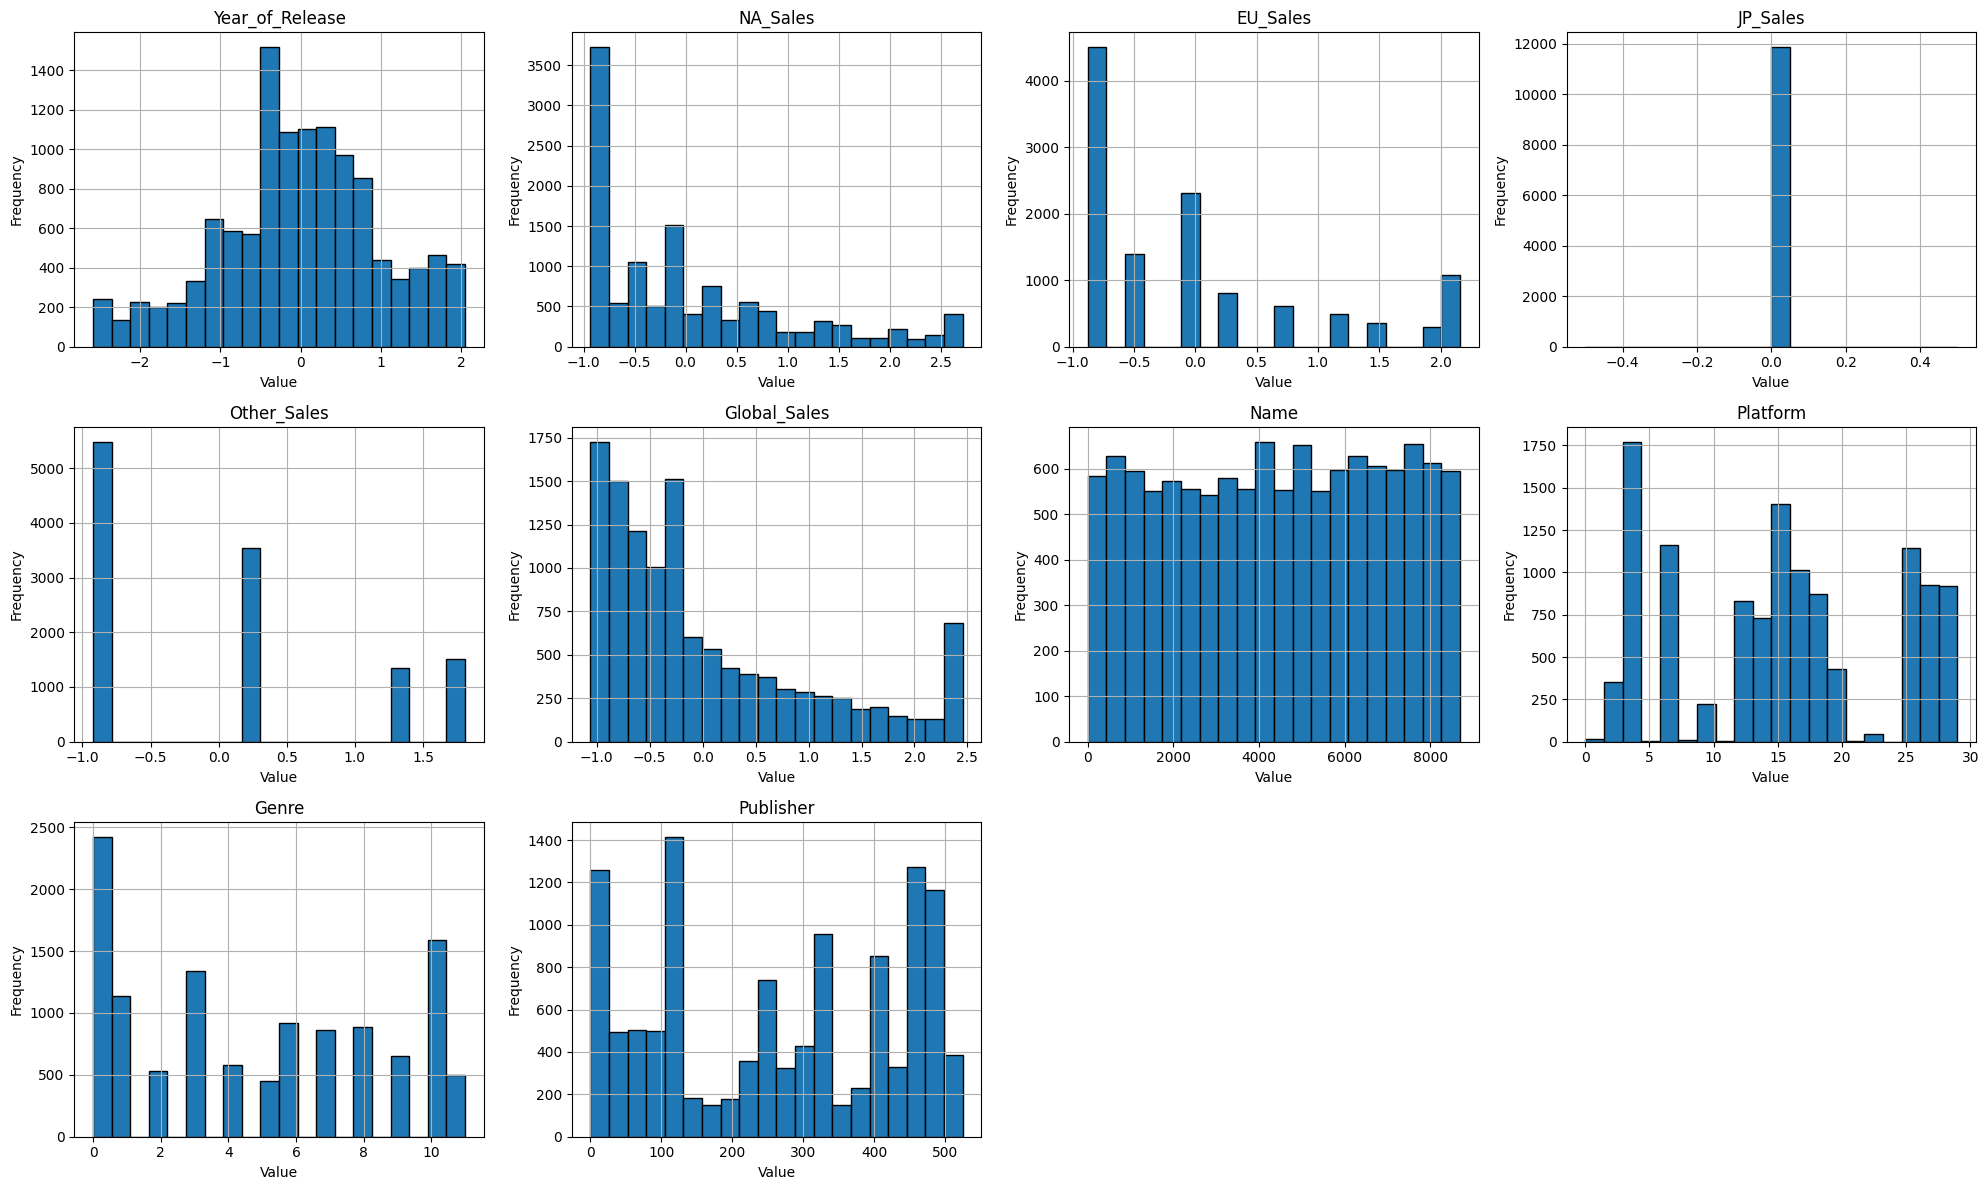

In [76]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]
  
# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
  
# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

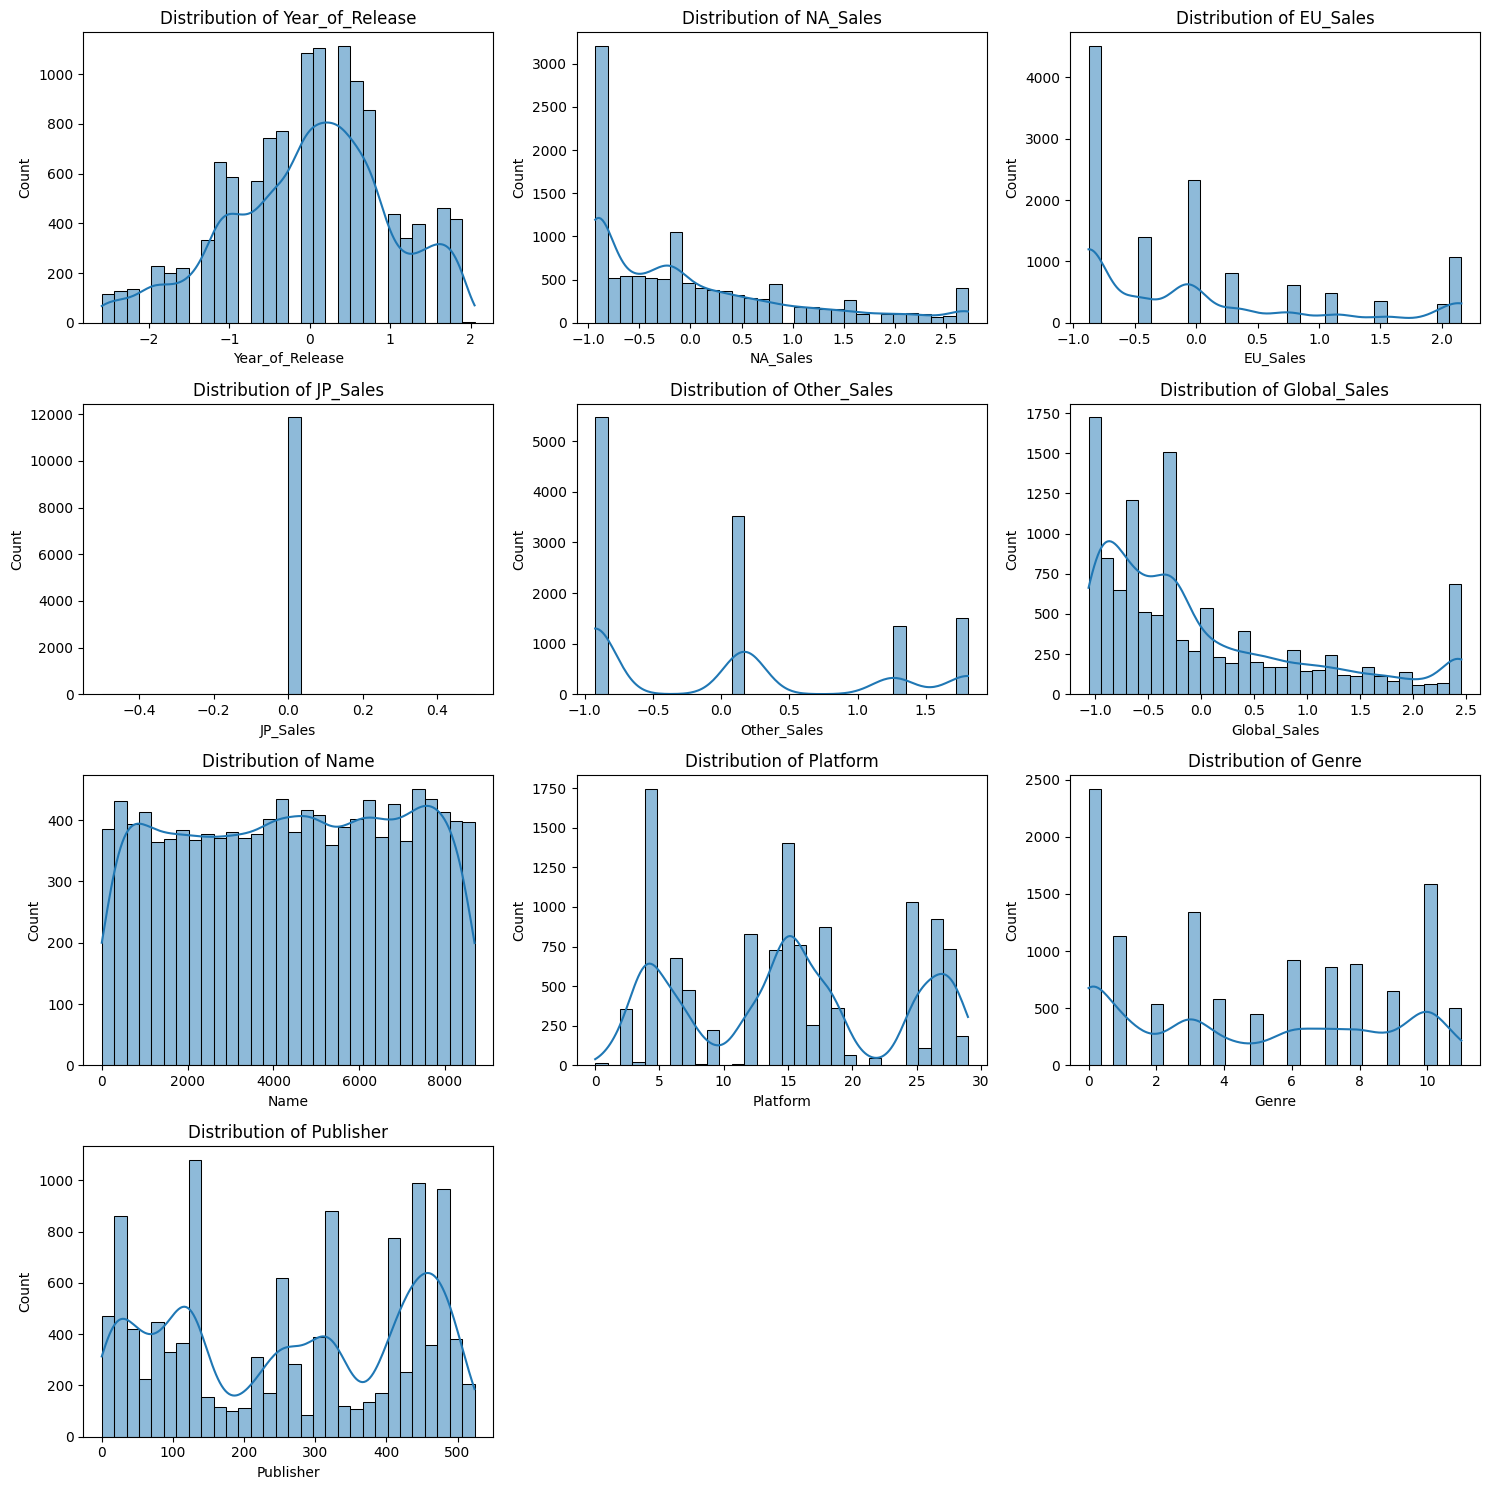

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

columns_to_plot = ['Year_of_Release', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Name', 'Platform', 'Genre', 'Publisher']

# Ubah ukuran grid menjadi 4 baris dan 3 kolom (total 12 slot)
plt.figure(figsize=(15, 15))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(4, 3, i)  # <--- Ubah (2, 3, i) menjadi (4, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

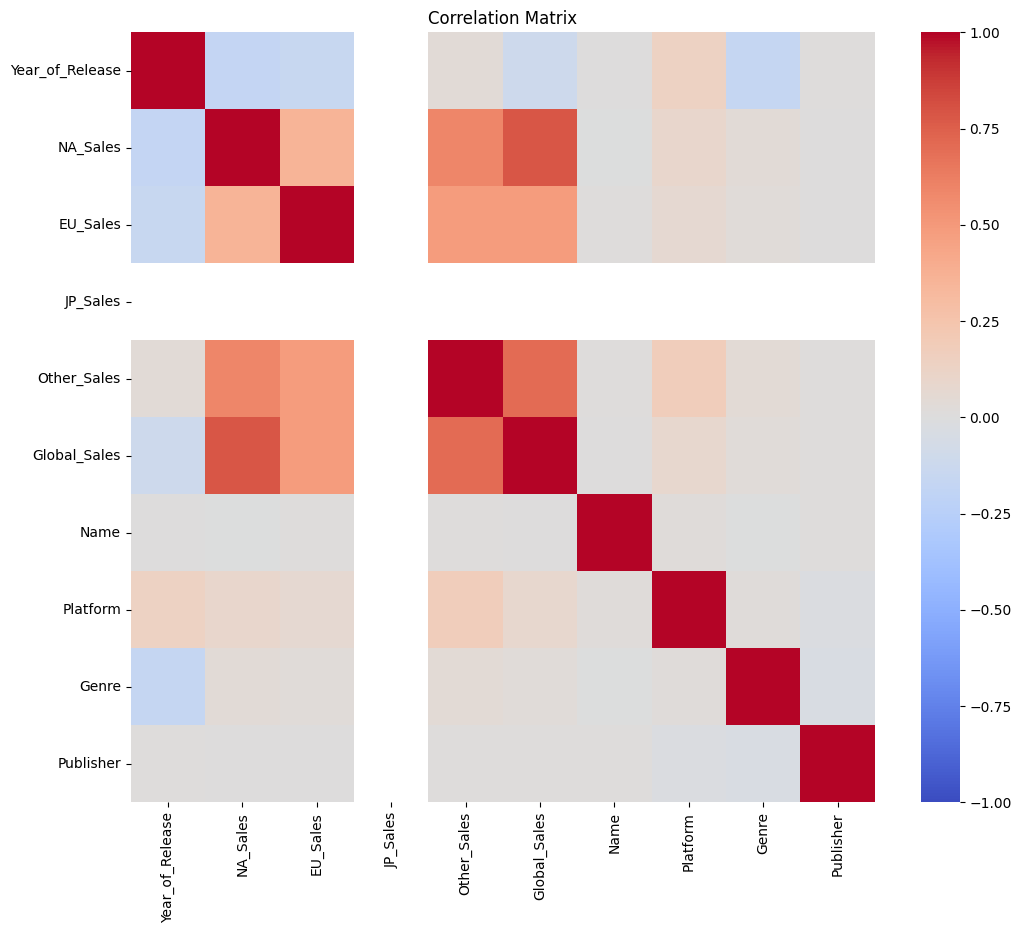

In [78]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()
  
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

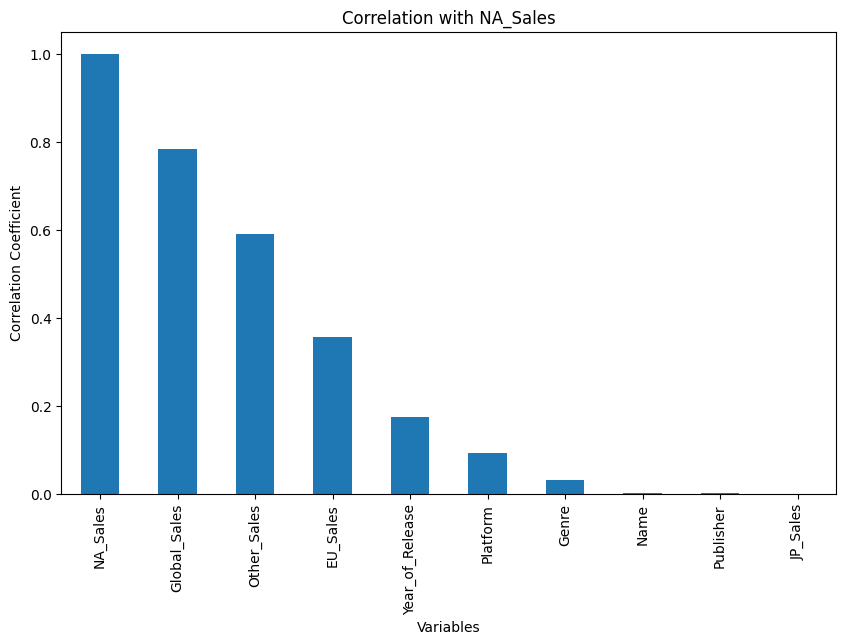

In [79]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['NA_Sales']
  
# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)
  
plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with NA_Sales')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [80]:
import sklearn

In [81]:
# Memisahkan fitur (X) dan target (y)
x = df_lencoder.drop(columns=['NA_Sales'])
y = df_lencoder['NA_Sales']

In [82]:
from sklearn.model_selection import train_test_split
  
# membagi dataset menjadi training dan testing 

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)


In [83]:
# menghitung panjang/jumlah data
print("Jumlah data: ", len(x))

# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(x_train))

# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(x_test))

Jumlah data:  11867
Jumlah data latih:  9493
Jumlah data test:  2374


In [84]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)
  
# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)
  
# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [85]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
  
# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}
  
# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.805619,1.028834,-0.000901


In [86]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)
  
# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.805619,1.028834,-0.000901
Linear Regression,0.398659,0.385380,0.625083


In [87]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)
  
# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.805619,1.028834,-0.000901
Linear Regression,0.398659,0.385380,0.625083
GradientBoostingRegressor,0.263078,0.217253,0.788645


In [90]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

['gbr_model.joblib']

In [91]:
# Memuat model dari file joblib
joblib_model = joblib.load('gbr_model.joblib')

In [92]:
from flask import Flask, request, jsonify
import joblib

# Inisialisasi aplikasi Flask
app = Flask(__name__)

# Memuat model yang telah disimpan
joblib_model = joblib.load('gbr_model.joblib')

@app.route('/predict', methods=['POST'])
def predict():
    data = request.json['data']
    prediction = joblib_model.predict(data)
    return jsonify({'prediction': prediction.tolist()})
    
if __name__ == '__main__':
    app.run(debug=True, use_reloader=False)

 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [17/Oct/2026 18:17:55] "GET / HTTP/1.1" 404 -
127.0.0.1 - - [17/Oct/2026 18:18:23] "GET /predict HTTP/1.1" 405 -
127.0.0.1 - - [17/Oct/2026 18:18:23] "GET /predict HTTP/1.1" 405 -
127.0.0.1 - - [17/Oct/2026 18:19:13] "GET /predict HTTP/1.1" 405 -
127.0.0.1 - - [17/Oct/2026 18:19:15] "GET /predict HTTP/1.1" 405 -
127.0.0.1 - - [17/Oct/2026 18:19:15] "GET /predict HTTP/1.1" 405 -
127.0.0.1 - - [17/Oct/2026 18:19:20] "GET /predict HTTP/1.1" 405 -
127.0.0.1 - - [17/Oct/2026 18:19:34] "GET / HTTP/1.1" 404 -


In [93]:
%tb

ConnectionError: HTTPConnectionPool(host='127.0.0.1', port=5000): Max retries exceeded with url: /predict (Caused by NewConnectionError("HTTPConnection(host='127.0.0.1', port=5000): Failed to establish a new connection: [WinError 10061] No connection could be made because the target machine actively refused it"))

In [ ]:
import requests

# URL endpoint Flask Anda
url = 'http://127.0.0.1:5000/predict'

# Siapkan data JSON yang akan dikirim (pastikan formatnya sesuai dengan input model Anda)
# Contoh di bawah mengirimkan array 2D karena model biasanya menerima format 2D
data_payload = {
  "model_type": "GradientBoostingRegressor",
  "library": "scikit-learn",
  "version": "1.8.0",
  "hyperparameters": {
    "n_estimators": 100,
    "learning_rate": 0.1,
    "loss": "squared_error",
    "criterion": "friedman_mse",
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "min_weight_fraction_leaf": 0.0,
    "subsample": 1.0,
    "max_features": null,
    "max_depth": 3,
    "min_impurity_decrease": 0.0,
    "ccp_alpha": 0.0,
    "init": null,
    "random_state": 456,
    "alpha": 0.9,
    "verbose": 0,
    "max_leaf_nodes": null,
    "warm_start": false,
    "validation_fraction": 0.1,
    "n_iter_no_change": null,
    "tol": 0.0001
  },
  "feature_names_in": [
    "Year_of_Release",
    "EU_Sales",
    "JP_Sales",
    "Other_Sales",
    "Global_Sales",
    "Name",
    "Platform",
    "Genre",
    "Publisher"
  ],
  "n_features_in": 9
} 

# Mengirim request POST dengan format JSON
response = requests.post(url, json=data_payload)

# Menampilkan hasil prediksi dari server Flask
print("Status Code:", response.status_code)
print("Hasil Respon:", response.json())